In [ ]:
! pip install cpi
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import numpy as np
import re
import cpi
from google.colab import drive


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.1/18.1 MB 65.3 MB/s eta 0:00:00


/tmp/ipykernel_522/2060387265.py:7: StaleDataWarning: CPI data is out of date. To accurately inflate to today's dollars, you must run `cpi.update()`.
  import cpi


In [ ]:
drive.mount("/content/drive/")

Mounted at /content/drive/


In [ ]:
storm_frames = []
for yr in range(1996, 2027):
  if(yr == 2017):
    df = pd.read_csv(f"/content/drive/MyDrive/Nino/raw_data/storm_events/StormEvents_details-ftp_v1.0_d{yr}_c20260519.csv.gz")
  elif (yr == 2022 or yr == 2026):
    df = pd.read_csv(f"/content/drive/MyDrive/Nino/raw_data/storm_events/StormEvents_details-ftp_v1.0_d{yr}_c20260625.csv.gz")
  elif (yr == 2024):
    df = pd.read_csv(f"/content/drive/MyDrive/Nino/raw_data/storm_events/StormEvents_details-ftp_v1.0_d{yr}_c20260421.csv.gz")
  elif (yr == 2025):
    df = pd.read_csv(f"/content/drive/MyDrive/Nino/raw_data/storm_events/StormEvents_details-ftp_v1.0_d{yr}_c20260526.csv.gz")
  else:
    df = pd.read_csv(f"/content/drive/MyDrive/Nino/raw_data/storm_events/StormEvents_details-ftp_v1.0_d{yr}_c20260323.csv.gz")
  storm_frames.append(df)

storm_events = pd.concat(storm_frames, ignore_index=True)
storm_events



/tmp/ipykernel_522/2552862938.py:12: DtypeWarning: Columns (26,28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"/content/drive/MyDrive/Nino/raw_data/storm_events/StormEvents_details-ftp_v1.0_d{yr}_c20260323.csv.gz")
/tmp/ipykernel_522/2552862938.py:12: DtypeWarning: Columns (28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"/content/drive/MyDrive/Nino/raw_data/storm_events/StormEvents_details-ftp_v1.0_d{yr}_c20260323.csv.gz")
/tmp/ipykernel_522/2552862938.py:12: DtypeWarning: Columns (28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"/content/drive/MyDrive/Nino/raw_data/storm_events/StormEvents_details-ftp_v1.0_d{yr}_c20260323.csv.gz")
/tmp/ipykernel_522/2552862938.py:12: DtypeWarning: Columns (29,34,35,37) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"/content/drive/MyDrive/Nino/raw_data/sto

,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,END_RANGE,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE
0,199610,29,1710,199610,30,600,2052149.0,5570068,ILLINOIS,17.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Strong gradient winds followed behind a line o...,NaN,PDC
1,199610,21,900,199610,21,900,2052748.0,5570362,OKLAHOMA,40.0,...,NaN,NaN,DURANT,NaN,NaN,NaN,NaN,Flash flood waters washed out a small bridge a...,NaN,PDC
2,199610,20,1915,199610,20,1915,2052749.0,5570363,OKLAHOMA,40.0,...,NaN,NaN,EMPIRE CITY,34.42,-98.03,34.42,-98.03,Hail as large as softballs broke out car and t...,NaN,PDC
3,199601,23,400,199601,24,2200,2404440.0,5537534,CALIFORNIA,6.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A storm that originated in the Gulf of Alaska ...,NaN,PDC
4,199601,17,900,199601,18,1800,2404601.0,5538413,MINNESOTA,27.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A major winter storm brought blizzard conditio...,NaN,PDC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1797968,202601,17,1700,202601,18,0,208826.0,1300662,MONTANA,30.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A strong low pressure system from the Canadian...,The BLM Zortman E mesonet site (MTM38) measure...,CSV
1797969,202601,17,2000,202601,18,1100,208826.0,1300670,MONTANA,30.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A strong low pressure system from the Canadian...,The McGuire Creek MT-24 DOT site (mtmcg) measu...,CSV
1797970,202601,17,2300,202601,18,1100,208826.0,1300674,MONTANA,30.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A strong low pressure system from the Canadian...,The BLM Vandalia N mesonet site (MTM34) measur...,CSV
1797971,202601,18,0,202601,18,1100,208826.0,1300661,MONTANA,30.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A strong low pressure system from the Canadian...,The Bloomfield CWOP mesonet site (G0525) measu...,CSV


In [ ]:
storm_events["EVENT_TYPE"].value_counts()

USABLE_EVENT_TYPES = [
    "Thunderstorm Wind",
    "Hail",
    "Flash Flood",
    "High Wind",
    "Winter Storm",
    "Winter Weather",
    "Heavy Snow",
    "Flood",
    "Tornado",
    "Heat",
    "Heavy Rain",
    "Strong Wind",
    "Excessive Heat",
    "Extreme Cold/Wind Chill",
    "Cold/Wind Chill",
    "Lightning",
    "Dense Fog",
    "Blizzard",
    "Ice Storm",
    "High Surf",
    "Funnel Cloud",
    "Wildfire",
    "Tropical Storm",
    "Coastal Flood",
    "Lake-Effect Snow",
    "Debris Flow",
    "Hurricane (Typhoon)",
    "Dust Storm",
    "Rip Current",
    "Storm Surge/Tide",
    "Avalanche",
    "Sleet",
    "Dense Smoke",
    "Tropical Depression",
    "Freezing Fog",
    "Lakeshore Flood",
    "Dust Devil",
    "Seiche",
    "Volcanic Ashfall",
    "Volcanic Ash",
    "Sneakerwave",
    "Tsunami",
]

storm_events = storm_events[storm_events["EVENT_TYPE"].isin(USABLE_EVENT_TYPES)]


# storm_events = storm_events[storm_events["EVENT_TYPE"].isin(["Lakeshore Flood", "Tropical Depression", "Storm Surge/Tide",
#                                                            "Hurricane (Typhoon)", "Debris Flow", "Coastal Flood", "Tropical Storm",
#                                                            "Ice Storm", "Blizzard", "Cold/Wind Chill",
#                                                            "Extreme Cold/Wind Chill", "Excessive Heat", "Heavy Rain",
#                                                            "Heat", "Flood", "Heavy Snow", "Winter Weather",
#                                                            "Winter Storm", "High Wind", "Flash Flood"])]

In [ ]:
# storm_events = storm_events[['YEAR','MONTH_NAME','STATE_FIPS','CZ_FIPS','CZ_TYPE','CZ_NAME','EVENT_TYPE', "EPISODE_ID", 'EVENT_ID',
#         'DEATHS_DIRECT','DEATHS_INDIRECT','INJURIES_DIRECT','INJURIES_INDIRECT',
#         'DAMAGE_PROPERTY','DAMAGE_CROPS']]
storm_events["CZ_TYPE"].value_counts() # counties, zones, and marine area (drop marine)

,count
CZ_TYPE,
C,1061472
Z,584689


In [ ]:
storm_events = storm_events[storm_events["CZ_TYPE"] != "M"] # drops marine areas
county_events = storm_events[storm_events["CZ_TYPE"] == "C"]
zone_events = storm_events[storm_events["CZ_TYPE"] == "Z"]

In [ ]:
# parse_damage defined early (used by recovery diagnostics and the split)
def parse_damage(x):
    if pd.isna(x): return np.nan
    s = str(x).strip().upper()
    if s in ("", "NAN"): return np.nan
    mult = {"K":1e3, "M":1e6, "B":1e9}
    if s[-1].isalpha():
        if s[-1] not in mult: return np.nan
        num = s[:-1].strip()
        if num in ("", ".", "-"): return np.nan
        return float(num) * mult[s[-1]]
    if s in (".", "-"): return np.nan
    try: return float(s)
    except ValueError: return np.nan


In [ ]:
# raw2 = storm_events.copy()
# def broadcast_frac(df):
#     g = df.groupby("EPISODE_ID")["DAMAGE_CROPS"].agg(
#         lambda s: (s.dropna().nunique()<=1) and (s.notna().sum()>1))
#     return g.mean() if len(g) else np.nan

# keep = ["Flash Flood","Flood","Coastal Flood","Lakeshore Flood","Heavy Rain",
#         "Storm Surge/Tide","Debris Flow","Hurricane (Typhoon)","Tropical Storm",
#         "Tropical Depression","High Surf","Winter Storm","Winter Weather","Heavy Snow",
#         "Blizzard","Ice Storm","Extreme Cold/Wind Chill","Cold/Wind Chill","Frost/Freeze",
#         "Heat","Excessive Heat","Drought","High Wind"]

# rows=[]
# for et in keep:
#     sub = raw2[raw2["EVENT_TYPE"]==et]
#     if len(sub)==0: continue
#     span = ((pd.to_datetime(sub["END_YEARMONTH"],format="%Y%m")
#            - pd.to_datetime(sub["BEGIN_YEARMONTH"],format="%Y%m")).dt.days/30.44).median()
#     rows.append({
#         "event": et, "rows": len(sub),
#         "median_span_mo": round(span,1),
#         "broadcast_frac": round(broadcast_frac(sub),2),
#         "deaths": int(sub[["DEATHS_DIRECT","DEATHS_INDIRECT"]].fillna(0).sum().sum()),
#         "prop_M": round(sub["DAMAGE_PROPERTY"].sum()/1e6),
#         "crop_M": round(sub["DAMAGE_CROPS"].sum()/1e6),
#     })
# print(pd.DataFrame(rows).sort_values("broadcast_frac", ascending=False).to_string(index=False))

In [ ]:
storm_events["DEATHS_DIRECT"].ne(0).sum()

np.int64(10786)

In [ ]:
# for all county-recorded events, just create geoid
county_events["GEOID"] = county_events["STATE_FIPS"].astype(int).astype(str).str.zfill(2) + county_events["CZ_FIPS"].astype(int).astype(str).str.zfill(3)

# for those recorded as zones, they must be converted to county-wide readings
cols = ['state','zone','wfo','zone_name','state_zone','county_name','county_fips','tz','region','lat','lon']
zones = pd.read_csv("/content/drive/MyDrive/Nino/raw_data/zone_to_county.txt", sep="|", names=cols, dtype=str)
zones["county_fips"] = zones["county_fips"].astype(str).str.zfill(5)
zones["zone"] = zones["zone"].astype(str).str.zfill(3)   # FIX: pad crosswalk zone to 3 chars

fips_to_abbr = {
    "01":"AL","02":"AK","04":"AZ","05":"AR","06":"CA","08":"CO","09":"CT","10":"DE","11":"DC","12":"FL",
    "13":"GA","15":"HI","16":"ID","17":"IL","18":"IN","19":"IA","20":"KS","21":"KY","22":"LA","23":"ME",
    "24":"MD","25":"MA","26":"MI","27":"MN","28":"MS","29":"MO","30":"MT","31":"NE","32":"NV","33":"NH",
    "34":"NJ","35":"NM","36":"NY","37":"NC","38":"ND","39":"OH","40":"OK","41":"OR","42":"PA","44":"RI",
    "45":"SC","46":"SD","47":"TN","48":"TX","49":"UT","50":"VT","51":"VA","53":"WA","54":"WV","55":"WI","56":"WY",
}
zone_events["STATE_ABBR"] = zone_events["STATE_FIPS"].astype(int).astype(str).str.zfill(2).map(fips_to_abbr)
zone_events["STATE_FIPS2"] = zone_events["STATE_FIPS"].astype(int).astype(str).str.zfill(2)
zone_events["CZ_FIPS"] = zone_events["CZ_FIPS"].astype(int).astype(str).str.zfill(3)   # FIX: int->str (was reading floats)

converted_zone_events = zone_events.merge(
    zones[["state", "zone", "county_fips"]],
    left_on=["STATE_ABBR", "CZ_FIPS"],
    right_on=["state", "zone"],
    how="left"
)


/tmp/ipykernel_522/4019158147.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  county_events["GEOID"] = county_events["STATE_FIPS"].astype(int).astype(str).str.zfill(2) + county_events["CZ_FIPS"].astype(int).astype(str).str.zfill(3)
/tmp/ipykernel_522/4019158147.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  zone_events["STATE_ABBR"] = zone_events["STATE_FIPS"].astype(int).astype(str).str.zfill(2).map(fips_to_abbr)
/tmp/ipykernel_522/4019158147.py:18: SettingWithCopyWarning: 
A value is trying to b

In [ ]:
converted_zone_events
print("unmatched:", converted_zone_events["county_fips"].isna().sum(), "of", len(converted_zone_events))
unmatched = converted_zone_events[converted_zone_events["county_fips"].isna()]
print(unmatched["STATE_ABBR"].value_counts().head(10))

pd.reset_option("display.max_rows")
# unmatched["CZ_NAME"].value_counts()
zones

unmatched: 72316 of 698275
STATE_ABBR
CA    10201
AK     8282
MT     7119
HI     4928
NM     4552
WA     3828
UT     3601
OR     3428
WV     2117
SC     1996
Name: count, dtype: int64


,state,zone,wfo,zone_name,state_zone,county_name,county_fips,tz,region,lat,lon
0,NM,201,ABQ,Northwest Plateau,NM201,McKinley,35031,M,nw,36.4270,-108.4064
1,NM,201,ABQ,Northwest Plateau,NM201,San Juan,35045,M,nw,36.4270,-108.4064
2,NM,202,ABQ,Chuska Mountains,NM202,McKinley,35031,M,nw,36.0409,-108.9296
3,NM,202,ABQ,Chuska Mountains,NM202,San Juan,35045,M,nw,36.0409,-108.9296
4,NM,203,ABQ,Far Northwest Highlands,NM203,Rio Arriba,35039,M,nc,36.6585,-107.1028
...,...,...,...,...,...,...,...,...,...,...,...
4870,NV,019,VEF,Spring Mountains-Red Rock Canyon,NV019,Nye,32023,P,sc,36.2348,-115.6791
4871,NV,020,VEF,Las Vegas Valley,NV020,Clark,32003,P,ss,36.1435,-115.1712
4872,NV,022,VEF,Southern Clark County,NV022,Clark,32003,P,ss,35.5358,-115.0222
4873,NV,025,VEF,Lake Mead - NV side,NV025,Clark,32003,P,ss,36.2015,-114.5111


In [ ]:
unmatched = converted_zone_events[converted_zone_events["county_fips"].isna()]
print("unmatched events:", len(unmatched))
print("total deaths in unmatched:", unmatched["DEATHS_DIRECT"].sum())
print("total injuries in unmatched:", unmatched["INJURIES_DIRECT"].sum())
# parse damage first, but roughly:
print("nonzero-damage unmatched rows:", (unmatched["DAMAGE_PROPERTY"] != "0.00K").sum())

unmatched events: 72316
total deaths in unmatched: 3484
total injuries in unmatched: 5663
nonzero-damage unmatched rows: 36859


In [ ]:
# how much impact is in each category
print(unmatched["STATE_ABBR"].value_counts())

# of the IN-SCOPE unmatched, how much impact
print("in-scope unmatched deaths:", unmatched["DEATHS_DIRECT"].sum())
print("in-scope unmatched nonzero-damage:", (unmatched["DAMAGE_PROPERTY"] != "0.00K").sum())

STATE_ABBR
CA    10201
AK     8282
MT     7119
HI     4928
NM     4552
WA     3828
UT     3601
OR     3428
WV     2117
SC     1996
VA     1940
ID     1662
PA     1615
FL     1596
AR     1480
WY     1438
TX     1326
MD     1230
LA     1172
NC     1101
AZ      948
ND      817
MI      571
GA      527
IL      466
IN      401
OK      393
NV      340
VT      310
NJ      263
NY      212
AL      198
MS      194
NE       34
CO       28
Name: count, dtype: int64
in-scope unmatched deaths: 3484
in-scope unmatched nonzero-damage: 36859


In [ ]:
# the actual unmatched (state, zone) pairs, most frequent first
missing = (unmatched.groupby(["STATE_ABBR","CZ_FIPS"])
           .size().sort_values(ascending=False).head(20))
print(missing)

# now check: do those pairs exist in the crosswalk at all?
zone_keys = set(zones["state"] + "|" + zones["zone"])
for (st, zn), n in missing.items():
    print(st, zn, n, (f"{st}|{zn}" in zone_keys))

STATE_ABBR  CZ_FIPS
HI          002        932
MT          009        888
TX          258        761
HI          008        656
SC          050        589
MT          048        568
HI          020        550
            012        534
CA          095        532
            069        528
MT          012        519
            010        493
CA          096        490
WA          042        477
OR          001        472
            002        458
UT          008        448
HI          013        447
PA          069        444
HI          005        437
dtype: int64
HI 002 932 False
MT 009 888 False
TX 258 761 False
HI 008 656 False
SC 050 589 False
MT 048 568 False
HI 020 550 False
HI 012 534 False
CA 095 532 False
CA 069 528 False
MT 012 519 False
MT 010 493 False
CA 096 490 False
WA 042 477 False
OR 001 472 False
OR 002 458 False
UT 008 448 False
HI 013 447 False
PA 069 444 False
HI 005 437 False


In [ ]:
print(unmatched["CZ_TYPE"].value_counts())


CZ_TYPE
Z    72316
Name: count, dtype: int64


In [ ]:
print(storm_events["CZ_TYPE"].apply(repr).value_counts().head())

CZ_TYPE
'C'    1061472
'Z'     584689
Name: count, dtype: int64


In [ ]:
# FIX v2: two-tier zone recovery.
# Cell 8 already did STEP 1 (crosswalk by state+zone, fanning out to counties).
# Here STEP 2 recovers crosswalk-unmatched zone rows by matching CZ_NAME to a TIGER
# county name WITHIN the same state, after stripping directional/qualifier words
# (NORTHERN, COASTAL, UPPER, LOWER, INLAND, ...) and taking the first token of a
# slash/ampersand multi-county descriptor. This recovers e.g. 'INLAND NEW HANOVER'->New Hanover,
# 'UPPER TERREBONNE'->Terrebonne, 'LOWER JEFFERSON'->Jefferson, recovering ~$110B of
# hurricane/tropical damage the old single-pass match missed (Ida, Gulf storms, etc.).
# Genuinely multi-county regional zones (wildfire complexes like 'Northeast Foothills/
# Sacramento Valley') and territories (Guam, Puerto Rico) remain unresolved by design.

county_gdf = gpd.read_file("/content/drive/MyDrive/Nino/raw_data/county_boundaries/tl_2018_us_county.shp")
county_gdf["GEOID"] = county_gdf["GEOID"].astype(str).str.zfill(5)
tiger_geoids = set(county_gdf["GEOID"])
county_gdf["NAME_U"] = county_gdf["NAME"].str.upper().str.strip()
name_to_geoid = (county_gdf.drop_duplicates(["STATEFP","NAME_U"])
                 .set_index(["STATEFP","NAME_U"])["GEOID"].to_dict())

_MODS = ['NORTHEAST','NORTHWEST','SOUTHEAST','SOUTHWEST','NORTHERN','SOUTHERN','EASTERN',
         'WESTERN','CENTRAL','COASTAL','INLAND','UPPER','LOWER','NORTH','SOUTH','EAST',
         'WEST','INTERIOR','METRO','GREATER']
def _clean_name(nm):
    s = str(nm).upper().strip()
    s = re.split(r'[/&]', s)[0].strip()
    toks = [t for t in re.split(r'\s+', s) if t not in _MODS]
    return ' '.join(toks).strip()

def recover_geoid(sf, nm):
    raw = str(nm).upper().strip()
    for cand in [raw, _clean_name(nm)]:
        if (sf, cand) in name_to_geoid: return name_to_geoid[(sf, cand)]
    for piece in re.split(r'[/&]', raw):
        c = _clean_name(piece)
        if (sf, c) in name_to_geoid: return name_to_geoid[(sf, c)]
    return np.nan

still_missing = converted_zone_events[converted_zone_events["county_fips"].isna()].copy()
still_missing["GEOID"] = [recover_geoid(sf, nm)
                          for sf, nm in zip(still_missing["STATE_FIPS2"], still_missing["CZ_NAME"])]
recovered  = still_missing[still_missing["GEOID"].notna()].copy()
unresolved = still_missing[still_missing["GEOID"].isna()].copy()
print("zone rows recovered by name (v2):", len(recovered))
print("zone rows still unresolved       :", len(unresolved),
      "| property $ set aside: %.2fB" % (unresolved["DAMAGE_PROPERTY"].map(parse_damage).sum()/1e9))


zone rows recovered by name (v2): 27318
zone rows still unresolved       : 44998 | property $ set aside: 36.27B


In [ ]:
recovered

,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE,STATE_ABBR,STATE_FIPS2,state,zone,county_fips,GEOID
12,199601,7,800,199601,7,1300,2404400.0,5536279,WYOMING,56.0,...,NaN,Winds were sustained at 40 to 45 MPH over part...,NaN,PDC,WY,56,NaN,NaN,NaN,56007
26,199601,12,100,199601,12,1000,1030972.0,5584224,VIRGINIA,51.0,...,NaN,The second storm in less than a week dumped lo...,NaN,PDC,VA,51,NaN,NaN,NaN,51085
53,199601,19,0,199601,19,400,2404282.0,5537217,NORTH CAROLINA,37.0,...,NaN,"An extremely strong cold front, preceded by he...",NaN,PDC,NC,37,NaN,NaN,NaN,37149
91,199601,16,2000,199601,18,1100,2404408.0,5536522,WYOMING,56.0,...,NaN,"Strong winds, snow and cold temperatures combi...",NaN,PDC,WY,56,NaN,NaN,NaN,56007
147,199601,20,800,199601,21,600,2404411.0,5536556,WYOMING,56.0,...,NaN,Winds were sustained between 40 and 50 MPH fro...,NaN,PDC,WY,56,NaN,NaN,NaN,56031
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
694938,202602,1,0,202602,1,756,210908.0,1320484,SOUTH CAROLINA,45.0,...,NaN,A winter storm impacted much of southeast Sout...,The local criteria for an Extreme Cold Warning...,CSV,SC,45,NaN,NaN,NaN,45019
695046,202602,2,0,202602,2,800,211300.0,1320194,SOUTH CAROLINA,45.0,...,NaN,High pressure and light/calm winds led to a st...,The South Carolina Department of Public Health...,CSV,SC,45,NaN,NaN,NaN,45013
695047,202602,1,0,202602,1,1200,210908.0,1319611,SOUTH CAROLINA,45.0,...,NaN,A winter storm impacted much of southeast Sout...,The South Carolina Department of Public Health...,CSV,SC,45,NaN,NaN,NaN,45019
695096,202602,24,1000,202602,28,2359,210963.0,1317946,OKLAHOMA,40.0,...,NaN,"Unseasonably warm temperatures, high wind, and...",NaN,CSV,OK,40,NaN,NaN,NaN,40079


In [ ]:
# what do the two sides actually look like?
print(still_missing["GEOID"].head(10).tolist())
print(list(tiger_geoids)[:10])
print(still_missing["GEOID"].dtype)

# is Shasta (known-real, known-present) in each?
print("06089" in tiger_geoids)
print((still_missing["GEOID"] == "06089").any())

[nan, '56007', '51085', nan, nan, '37149', '56007', '56031', '56031', nan]
['37061', '54075', '13129', '42009', '19099', '54095', '26107', '40131', '42097', '21139']
object
True
False


In [ ]:
# zone rows matched by the crosswalk
zone_matched = converted_zone_events[converted_zone_events["county_fips"].notna()].copy()
zone_matched["GEOID"] = zone_matched["county_fips"].astype(str).str.zfill(5)

# county_events already has GEOID; recovered (name-matched) already has GEOID
all_events = pd.concat([county_events, zone_matched, recovered], ignore_index=True)
all_events


,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE,GEOID,STATE_ABBR,STATE_FIPS2,state,zone,county_fips
0,199610,21,900,199610,21,900,2052748.0,5570362,OKLAHOMA,40.0,...,NaN,Flash flood waters washed out a small bridge a...,NaN,PDC,40013,NaN,NaN,NaN,NaN,NaN
1,199610,20,1915,199610,20,1915,2052749.0,5570363,OKLAHOMA,40.0,...,-98.03,Hail as large as softballs broke out car and t...,NaN,PDC,40137,NaN,NaN,NaN,NaN,NaN
2,199601,17,2250,199601,17,2250,2404529.0,5535851,TEXAS,48.0,...,-97.15,"The ""Best for Less"" hotel office roof was blow...",NaN,PDC,48309,NaN,NaN,NaN,NaN,NaN
3,199601,18,845,199601,18,850,1000285.0,5535517,TENNESSEE,47.0,...,-88.97,Two homes were damaged and 18 golf cart houses...,NaN,PDC,47053,NaN,NaN,NaN,NaN,NaN
4,199601,18,1100,199601,18,1100,1000504.0,5535339,ILLINOIS,17.0,...,-89.07,"Thunderstorm winds destroyed a large shed, ble...",NaN,PDC,17113,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1714744,202602,1,0,202602,1,756,210908.0,1320484,SOUTH CAROLINA,45.0,...,NaN,A winter storm impacted much of southeast Sout...,The local criteria for an Extreme Cold Warning...,CSV,45019,SC,45,NaN,NaN,NaN
1714745,202602,2,0,202602,2,800,211300.0,1320194,SOUTH CAROLINA,45.0,...,NaN,High pressure and light/calm winds led to a st...,The South Carolina Department of Public Health...,CSV,45013,SC,45,NaN,NaN,NaN
1714746,202602,1,0,202602,1,1200,210908.0,1319611,SOUTH CAROLINA,45.0,...,NaN,A winter storm impacted much of southeast Sout...,The South Carolina Department of Public Health...,CSV,45019,SC,45,NaN,NaN,NaN
1714747,202602,24,1000,202602,28,2359,210963.0,1317946,OKLAHOMA,40.0,...,NaN,"Unseasonably warm temperatures, high wind, and...",NaN,CSV,40079,OK,40,NaN,NaN,NaN


In [ ]:
mask = all_events["GEOID"].str.contains(r"\.", na=False)   # the broken float ones
all_events.loc[mask, "GEOID"] = (
    all_events.loc[mask, "STATE_FIPS"].astype(float).astype(int).astype(str).str.zfill(2)
    + all_events.loc[mask, "CZ_FIPS"].astype(float).astype(int).astype(str).str.zfill(3)
)

In [ ]:
print(all_events["GEOID"].isin(tiger_geoids).all())          # want True
print((~all_events["GEOID"].isin(tiger_geoids)).sum(), "bad rows")
print(all_events.loc[~all_events["GEOID"].isin(tiger_geoids), "GEOID"].str[:2].value_counts().head())

False
6527 bad rows
GEOID
99    5057
02     555
97     336
96     238
98     222
Name: count, dtype: int64


In [ ]:
all_events = all_events[all_events["GEOID"].isin(tiger_geoids)]
print(all_events["GEOID"].isin(tiger_geoids).all(), len(all_events))

True 1708222


In [ ]:
all_events = all_events.drop(columns=[c for c in ["state","zone","county_fips","STATE_ABBR","STATE_FIPS2","NAME_U"] if c in all_events.columns])
all_events


,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE,GEOID
0,199610,21,900,199610,21,900,2052748.0,5570362,OKLAHOMA,40.0,...,NaN,DURANT,NaN,NaN,NaN,NaN,Flash flood waters washed out a small bridge a...,NaN,PDC,40013
1,199610,20,1915,199610,20,1915,2052749.0,5570363,OKLAHOMA,40.0,...,NaN,EMPIRE CITY,34.42,-98.03,34.42,-98.03,Hail as large as softballs broke out car and t...,NaN,PDC,40137
2,199601,17,2250,199601,17,2250,2404529.0,5535851,TEXAS,48.0,...,NaN,WACO,31.55,-97.15,31.55,-97.15,"The ""Best for Less"" hotel office roof was blow...",NaN,PDC,48309
3,199601,18,845,199601,18,850,1000285.0,5535517,TENNESSEE,47.0,...,NaN,GEORGETOWN,36.02,-88.97,36.02,-88.97,Two homes were damaged and 18 golf cart houses...,NaN,PDC,47053
4,199601,18,1100,199601,18,1100,1000504.0,5535339,ILLINOIS,17.0,...,NaN,HEYWORTH,40.53,-89.07,40.32,-89.07,"Thunderstorm winds destroyed a large shed, ble...",NaN,PDC,17113
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1714744,202602,1,0,202602,1,756,210908.0,1320484,SOUTH CAROLINA,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,A winter storm impacted much of southeast Sout...,The local criteria for an Extreme Cold Warning...,CSV,45019
1714745,202602,2,0,202602,2,800,211300.0,1320194,SOUTH CAROLINA,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,High pressure and light/calm winds led to a st...,The South Carolina Department of Public Health...,CSV,45013
1714746,202602,1,0,202602,1,1200,210908.0,1319611,SOUTH CAROLINA,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,A winter storm impacted much of southeast Sout...,The South Carolina Department of Public Health...,CSV,45019
1714747,202602,24,1000,202602,28,2359,210963.0,1317946,OKLAHOMA,40.0,...,NaN,NaN,NaN,NaN,NaN,NaN,"Unseasonably warm temperatures, high wind, and...",NaN,CSV,40079


In [ ]:
import numpy as np, pandas as pd

# 0. load population/features panel (all years)
pop = pd.read_parquet("/content/drive/MyDrive/Nino/intermediate_merged_data/precip_soil_nino_density_poverty.parquet")
pop = pop[["GEOID","date","population"]].copy()      # only what the split needs
pop["GEOID"] = pop["GEOID"].astype(str).str.zfill(5)
pop = pop.drop_duplicates(["GEOID","date"])   # FIX: guard against merge row-explosion

# 1. parse damage strings -> float dollars (blank stays NaN, "0.00K" -> 0)
def parse_damage(x):
    if pd.isna(x): return np.nan
    s = str(x).strip().upper()
    if s in ("", "NAN"): return np.nan
    mult = {"K":1e3, "M":1e6, "B":1e9}
    if s[-1].isalpha():
        if s[-1] not in mult:          # T, H, or any stray letter -> unparseable
            return np.nan
        num = s[:-1].strip()
        if num in ("", ".", "-"): return np.nan
        return float(num) * mult[s[-1]]
    if s in (".", "-"): return np.nan
    try:
        return float(s)
    except ValueError:
        return np.nan

ev = all_events.copy()
ev["GEOID"] = ev["GEOID"].astype(str).str.zfill(5)
for c in ["DAMAGE_PROPERTY","DAMAGE_CROPS"]:
    ev[c] = ev[c].map(parse_damage)

# 2. build a 'date' key matching the parquet ("YYYY-MM")
month_num = {m:i for i,m in enumerate(
    ["January","February","March","April","May","June","July",
     "August","September","October","November","December"], start=1)}
ev["date"] = ev["YEAR"].astype(int).astype(str) + "-" + \
             ev["MONTH_NAME"].map(month_num).astype(int).astype(str).str.zfill(2)

# 3. attach time-correct population
ev = ev.merge(pop, on=["GEOID","date"], how="left")

# 4. population-weighted split across each original event's counties
#    denominator = total pop of all counties the SAME event was fanned to
val_cols = ["DEATHS_DIRECT","DEATHS_INDIRECT","INJURIES_DIRECT",
            "INJURIES_INDIRECT","DAMAGE_PROPERTY","DAMAGE_CROPS"]

ev["_popsum"] = ev.groupby("EVENT_ID")["population"].transform("sum")
ev["_n"]      = ev.groupby("EVENT_ID")["GEOID"].transform("size")   # counties per event

# share: population-weighted where pop is available; fall back to equal split
ev["pop_share"] = np.where(
    ev["_popsum"] > 0,
    ev["population"] / ev["_popsum"],
    1.0 / ev["_n"]
)

# single-county events get share == 1 automatically (n=1, pop/pop)
for c in val_cols:
    ev[c] = ev[c] * ev["pop_share"]

# 5. aggregate to county-month
county_month = (ev.groupby(["GEOID","date"])[val_cols]
                  .sum(min_count=1)            # keeps all-NaN groups as NaN, not 0
                  .reset_index())

_t = (ev.groupby(["GEOID","date","EVENT_TYPE"])["DAMAGE_PROPERTY"]
        .sum(min_count=1).reset_index()
        .sort_values("DAMAGE_PROPERTY", ascending=False, na_position="last")
        .drop_duplicates(["GEOID","date"]))

county_month = county_month.merge(_t[["GEOID","date","EVENT_TYPE"]],
                                  on=["GEOID","date"], how="left")

# 6. verification
print("share sums to 1 per event:",
      np.allclose(ev.groupby("EVENT_ID")["pop_share"].sum().dropna(), 1.0))
print("national property total (post-split):", county_month["DAMAGE_PROPERTY"].sum())
print(county_month.sort_values("DAMAGE_PROPERTY", ascending=False).head())

# 7. CONSERVATION CHECK: post-split national total should ~= source (C+Z) per year
_src = (all_events.assign(_p=all_events["DAMAGE_PROPERTY"] if all_events["DAMAGE_PROPERTY"].dtype!='O'
                          else all_events["DAMAGE_PROPERTY"].map(parse_damage))
        .assign(_y=all_events["YEAR"].astype(int)).groupby("_y")["_p"].sum())
_post = county_month.assign(_y=county_month["date"].str[:4].astype(int)).groupby("_y")["DAMAGE_PROPERTY"].sum()
_chk = pd.DataFrame({"source":_src/1e9,"post_split":_post/1e9}).fillna(0)
_chk["kept_pct"] = 100*_chk["post_split"]/_chk["source"].replace(0, np.nan)
print("\n=== CONSERVATION (nominal $B) ===")
print(_chk.round(2).to_string())


share sums to 1 per event: True
national property total (post-split): 505745171050.0001
        GEOID     date  DEATHS_DIRECT  DEATHS_INDIRECT  INJURIES_DIRECT  \
193109  22071  2005-08          638.0              0.0              0.0   
314561  34025  2012-10            0.0              1.0              0.0   
315182  34029  2012-10            2.0              3.0              0.0   
469761  48201  2017-08           37.0              2.0              0.0   
467002  48167  2017-08            3.0              3.0              0.0   

        INJURIES_INDIRECT  DAMAGE_PROPERTY  DAMAGE_CROPS        EVENT_TYPE  
193109                0.0     2.146000e+10           NaN  Storm Surge/Tide  
314561                1.0     1.175004e+10           0.0     Coastal Flood  
315182                0.0     1.104000e+10           0.0     Coastal Flood  
469761                0.0     1.000073e+10      100000.0       Flash Flood  
467002                0.0     1.000020e+10       10000.0       Flash Flood  

In [ ]:
# county_month.to_parquet("/content/drive/MyDrive/Nino/intermediate_merged_data/storm_events.parquet")

In [ ]:
county_month

,GEOID,date,DEATHS_DIRECT,DEATHS_INDIRECT,INJURIES_DIRECT,INJURIES_INDIRECT,DAMAGE_PROPERTY,DAMAGE_CROPS,EVENT_TYPE
0,01001,1996-02,0.0,0.0,0.0,0.0,NaN,NaN,Cold/Wind Chill
1,01001,1996-03,0.0,0.0,0.0,0.0,36000.0,1020000.0,Hail
2,01001,1996-04,0.0,0.0,0.0,0.0,27000.0,2000.0,Thunderstorm Wind
3,01001,1996-05,0.0,0.0,0.0,0.0,10000.0,0.0,Hail
4,01001,1996-08,0.0,0.0,0.0,0.0,10000.0,0.0,Flash Flood
...,...,...,...,...,...,...,...,...,...
555883,56045,2025-03,0.0,0.0,0.0,0.0,NaN,0.0,Winter Storm
555884,56045,2025-07,0.0,0.0,0.0,0.0,0.0,0.0,Thunderstorm Wind
555885,56045,2025-08,0.0,0.0,0.0,0.0,0.0,0.0,Thunderstorm Wind
555886,56045,2025-09,0.0,0.0,0.0,0.0,0.0,0.0,Thunderstorm Wind


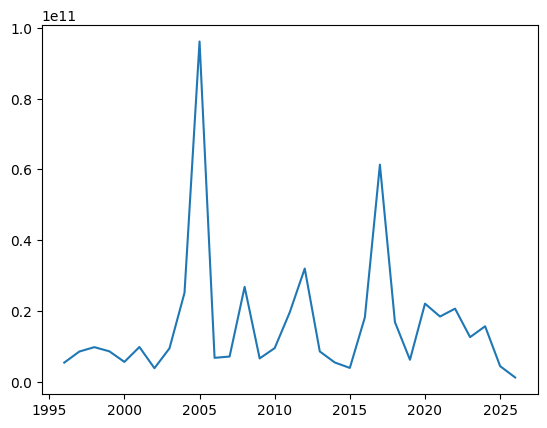

In [ ]:
# PRE-INFLATION ADJUSTMENT
yearly = county_month.groupby(county_month["date"].str[0:4].astype(int))
yearly = yearly["DAMAGE_PROPERTY"].sum()

plt.plot(yearly.index, yearly.values)
plt.show()

In [ ]:
# # adjust monetary values for inflation with cpi
# cpi.update()

# def adjust_damage_inflation(row):
#   val = row["DAMAGE_PROPERTY"]
#   year = int(row["date"][0:4])
#   if pd.isna(val) or year > 2025:
#     return val
#   return cpi.inflate(val, year)

# def adjust_crops_inflation(row):
#   val = row["DAMAGE_CROPS"]
#   year = int(row["date"][0:4])
#   if pd.isna(val) or year > 2025:
#     return val
#   return cpi.inflate(val, year)

# # .apply() gets each row in the table and applies a given function
# county_month["DAMAGE_PROPERTY"] = county_month.apply(adjust_damage_inflation, axis=1)
# county_month["DAMAGE_CROPS"] = county_month.apply(adjust_crops_inflation, axis=1)

In [ ]:
for y in [2005, 2012, 2017, 2020, 2025]:
    tot = county_month[county_month["date"].str[:4].astype(int)==y]["DAMAGE_PROPERTY"].sum()
    print(y, f"${tot/1e9:.2f}B")

2005 $96.13B
2012 $31.97B
2017 $61.33B
2020 $22.05B
2025 $4.39B


In [ ]:
# above code took forever b/c it requires 1.2m tasks
# simpler, faster version:

# get the year feature beforehand
county_month["year"] = county_month["date"].str[0:4].astype(int)

# get unique years instead of going through every row
unique_years = [y for y in county_month["year"].unique() if y <= 2025]

# create a dictionary for each unique year that holds the inflation factor, or what 1 dollar in x year means now
inflation_factors = {year : cpi.inflate(1,year) for year in unique_years}

# add the inflation factor across all rows
county_month["inflation_factor"] = county_month["year"].map(inflation_factors).fillna(1.0)

# now apply across all damage and crop costs
county_month["DAMAGE_PROPERTY"] = county_month["DAMAGE_PROPERTY"] * county_month["inflation_factor"]
county_month["DAMAGE_CROPS"] = county_month["DAMAGE_CROPS"] * county_month["inflation_factor"]

county_month.drop(columns=["year", "inflation_factor"], inplace=True)

In [ ]:
county_month["date"].sort_values()

,date
6008,1996-01
166008,1996-01
381042,1996-01
380819,1996-01
166250,1996-01
...,...
375903,2026-03
36240,2026-03
77763,2026-03
133568,2026-03


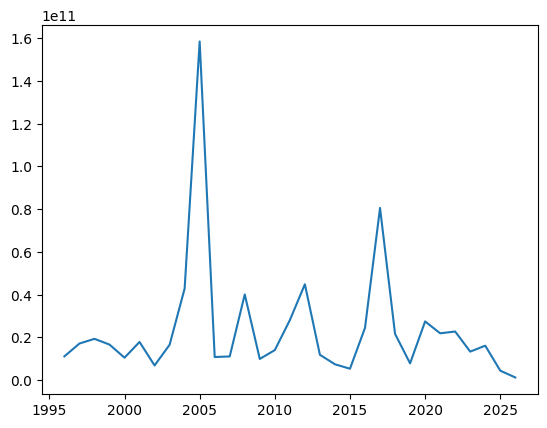

In [ ]:
# POST INFLATION ADJUSTMENT

# real_damages = county_month[county_month["DAMAGE_PROPERTY"].notna()]
# plt.plot(real_damages["date"].str[0:4].astype(int), real_damages["DAMAGE_PROPERTY"].astype(float))
# plt.show()

# adds up every row with the same year, going from 600k rows to 30 something
yearly = county_month.groupby(county_month["date"].str[0:4].astype(int))
yearly = yearly["DAMAGE_PROPERTY"].sum()

plt.plot(yearly.index, yearly.values)
plt.show()

In [ ]:
county_month = county_month.drop(columns=["INJURIES_DIRECT", "INJURIES_INDIRECT"])
county_month["DEATHS_TOTAL"] = county_month["DEATHS_DIRECT"].fillna(0) + county_month["DEATHS_INDIRECT"].fillna(0)

In [ ]:
county_month[county_month["DEATHS_DIRECT"].notna()].sort_values(by="DEATHS_DIRECT") # COUNTING STORM EVENTS OUT OF SCOPE

,GEOID,date,DEATHS_DIRECT,DEATHS_INDIRECT,DAMAGE_PROPERTY,DAMAGE_CROPS,EVENT_TYPE,DEATHS_TOTAL
369229,39057,2016-04,0.0,0.0,1.341390e+03,0.000000,High Wind,0.0
369221,39057,2015-03,0.0,0.0,NaN,NaN,Winter Weather,0.0
369222,39057,2015-04,0.0,0.0,6.791559e+03,0.000000,Thunderstorm Wind,0.0
369223,39057,2015-05,0.0,0.0,1.086649e+06,0.000000,Tornado,0.0
369224,39057,2015-06,0.0,0.0,1.018734e+04,0.000000,Thunderstorm Wind,0.0
...,...,...,...,...,...,...,...,...
194344,22087,2005-08,140.0,0.0,1.582516e+10,NaN,Storm Surge/Tide,140.0
12942,04013,2020-07,146.0,0.0,0.000000e+00,0.000000,Tornado,146.0
263444,29097,2011-05,159.0,3.0,4.007503e+09,0.000000,Tornado,162.0
12971,04013,2023-07,211.0,166.0,1.901850e+05,52829.157669,Thunderstorm Wind,377.0


In [ ]:
print((county_month["DEATHS_TOTAL"] == 0).mean())          # fraction zero
print(county_month["DEATHS_TOTAL"].describe())

0.9796020061595141
count    555888.000000
mean          0.039227
std           1.313781
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         638.000000
Name: DEATHS_TOTAL, dtype: float64


In [ ]:
county_month[county_month["date"].str[0:4].astype(int) == 2025]["DAMAGE_PROPERTY"].sum()

np.float64(4387070160.0)

In [ ]:
for y in [2005, 2012, 2017, 2020, 2025]:
    tot = county_month[county_month["date"].str[:4].astype(int)==y]["DAMAGE_PROPERTY"].sum()
    print(y, f"${tot/1e9:.2f}B")

2005 $158.47B
2012 $44.83B
2017 $80.56B
2020 $27.43B
2025 $4.39B


In [ ]:
# 1. Louisiana + Mississippi, Aug-Sep 2005 — is Katrina present and at full scale?
kat = county_month[(county_month["date"].isin(["2005-08","2005-09"])) &
                   (county_month["GEOID"].str[:2].isin(["22","28"]))]
print(kat.sort_values("DAMAGE_PROPERTY", ascending=False).head(10))
print("LA+MS Aug-Sep 2005 total:", kat["DAMAGE_PROPERTY"].sum()/1e9, "B")

# 2. biggest single county-months in all of 2005 — do the known giants appear?
y05 = county_month[county_month["date"].str[:4]=="2005"]
print(y05.sort_values("DAMAGE_PROPERTY", ascending=False).head(15))

        GEOID     date  DEATHS_DIRECT  DEATHS_INDIRECT  DAMAGE_PROPERTY  \
193109  22071  2005-08          638.0              0.0     3.537582e+10   
194344  22087  2005-08          140.0              0.0     1.582516e+10   
244473  28047  2005-08           97.0              0.0     1.412725e+10   
193459  22075  2005-08            2.0              0.0     1.165457e+10   
195264  22103  2005-08            2.0              0.0     9.181887e+09   
244324  28045  2005-08           57.0              0.0     7.995000e+09   
245449  28059  2005-08           13.0              0.0     5.522320e+09   
189465  22023  2005-09            0.0              0.0     4.533248e+09   
196405  22117  2005-08            2.0              0.0     3.066124e+09   
191523  22051  2005-08           27.0              0.0     3.052244e+09   

        DAMAGE_CROPS           EVENT_TYPE  DEATHS_TOTAL  
193109           NaN     Storm Surge/Tide         638.0  
194344           NaN     Storm Surge/Tide         140.0  


## Validation: per-year reconciliation vs raw NOAA source

In [ ]:
# VALIDATION: reconcile pipeline vs raw NOAA source, per year
# Rebuild raw non-marine annual property totals straight from the source
# and compare to county_month. In-scope retention should be ~97-100% every year.
import glob
raw_rows = []
for yr in range(1996, 2027):
    f = glob.glob(f"/content/drive/MyDrive/Nino/raw_data/storm_events/StormEvents_details-ftp_v1.0_d{yr}_c*.csv.gz")[0]
    d = pd.read_csv(f, low_memory=False, usecols=['CZ_TYPE','DAMAGE_PROPERTY'])
    d['p'] = d['DAMAGE_PROPERTY'].map(parse_damage)
    raw_rows.append({'year': yr, 'raw_noM': d[d.CZ_TYPE!='M']['p'].sum()/1e9})
recon = pd.DataFrame(raw_rows).set_index('year')
cm = county_month.copy()
cm['year'] = cm['date'].str[:4].astype(int)
recon['pipeline'] = cm.groupby('year')['DAMAGE_PROPERTY'].sum()/1e9
recon['kept_%'] = (100*recon['pipeline']/recon['raw_noM']).round(1)
print(recon.round(2).to_string())
print('OVERALL kept vs non-marine: %.1f%%' % (100*recon['pipeline'].sum()/recon['raw_noM'].sum()))

# note this is after inflation, hence kept_% exceeding 100% the farther from modern day you get

      raw_noM  pipeline  kept_%
year                           
1996     6.03     11.07   183.7
1997     9.35     17.08   182.6
1998    11.59     19.28   166.3
1999     8.72     16.59   190.2
2000     5.62     10.46   186.1
2001    10.03     17.82   177.7
2002     4.10      6.82   166.4
2003    10.25     16.50   160.9
2004    25.35     42.82   168.9
2005    96.67    158.47   163.9
2006     7.07     10.76   152.2
2007     7.36     11.04   150.0
2008    27.11     40.06   147.8
2009     6.77      9.87   145.7
2010     9.52     14.01   147.2
2011    20.62     28.03   136.0
2012    32.79     44.83   136.7
2013     8.82     11.81   134.0
2014     5.51      7.38   133.9
2015     4.40      5.29   120.2
2016    18.22     24.40   133.9
2017    80.40     80.56   100.2
2018    37.61     21.59    57.4
2019     6.24      7.80   125.1
2020    26.80     27.43   102.3
2021    19.11     21.88   114.5
2022    20.69     22.70   109.7
2023    16.63     13.30    80.0
2024    15.74     16.07   102.1
2025    

In [ ]:
# dont need damage crops if we're just predicting property damage
county_month.drop(columns=["DAMAGE_CROPS", "DEATHS_DIRECT", "DEATHS_INDIRECT"], inplace=True)
county_month.sort_values(by="DEATHS_TOTAL")

,GEOID,date,DAMAGE_PROPERTY,EVENT_TYPE,DEATHS_TOTAL
368814,39053,2021-04,0.000000e+00,Funnel Cloud,0.0
368805,39053,2019-12,1.007422e+04,Flood,0.0
368807,39053,2020-04,0.000000e+00,Hail,0.0
368808,39053,2020-06,2.114683e+04,Thunderstorm Wind,0.0
368809,39053,2020-07,6.219654e+03,Flash Flood,0.0
...,...,...,...,...,...
12942,04013,2020-07,0.000000e+00,Tornado,146.0
263444,29097,2011-05,4.007503e+09,Tornado,162.0
12961,04013,2022-07,6.211254e+06,Thunderstorm Wind,222.0
12971,04013,2023-07,1.901850e+05,Thunderstorm Wind,377.0


In [ ]:
county_month["DAMAGE_PROPERTY"].isna().sum()
county_month
# now create two features:
  # for a prediction time t, have a feature with casualty totals for county x for all months from t-5years to t
  # for a prediction time t, have a feature with damage totals for county x for all months from t-5years to t

# and two labels:
  # for a prediction time t, have a label for casualty totalts for county x for all months from t+3 to t+6
  # for a prediction time t, have a label for damage totals for county x for all monhts from t+3 to t+6

# first, need to make a df containing every county and every month
tiger = gpd.read_file("/content/drive/MyDrive/Nino/raw_data/county_boundaries/tl_2018_us_county.shp")
geoids = sorted(tiger["GEOID"].astype(str).str.zfill(5).unique())
# remove alaska, hawaai, and territories
geoids = sorted(g for g in geoids if g[:2] not in ("02", "15") and int(g[:2]) <= 56)
len(geoids)

3108

In [ ]:
# now get the list of all months
months = pd.period_range("1996-01", "2026-03", freq="M").astype(str)
# and combine the counties and months
grid = pd.MultiIndex.from_product([geoids, months], names=["GEOID", "date"]).to_frame(index=False)

# combine this ultimate grid and events df
panel = grid.merge(county_month, on=["GEOID", "date"], how="left")
val_cols = ["DAMAGE_PROPERTY", "DEATHS_TOTAL"]
panel[val_cols] = panel[val_cols].fillna(0.0)

# soft so that shifting and summing values follows calendar order
panel = panel.sort_values(by=["GEOID", "date"])
panel["damage_label_t+3"] = panel.groupby("GEOID")["DAMAGE_PROPERTY"].transform(lambda s: s.shift(-3))
# changed line below from -3, -4, -5 to -1, -2, -3 in hopes of increasing predictability
# panel["damage_label"] = panel.groupby("GEOID")["DAMAGE_PROPERTY"].transform(lambda s: s.shift(-1) + s.shift(-2) + s.shift(-3))
panel["damage_label"] = panel.groupby("GEOID")["DAMAGE_PROPERTY"].transform(lambda s: s.shift(-1))


panel["death_label_t+3"] = panel.groupby("GEOID")["DEATHS_TOTAL"].transform(lambda s: s.shift(-3))

# panel["death_label"] = panel.groupby("GEOID")["DEATHS_TOTAL"].transform(lambda s: s.shift(-3) + s.shift(-4) + s.shift(-5))
panel["death_label"] = panel.groupby("GEOID")["DEATHS_TOTAL"].transform(lambda s: s.shift(-1))
panel.head(10)

,GEOID,date,DAMAGE_PROPERTY,EVENT_TYPE,DEATHS_TOTAL,damage_label_t+3,damage_label,death_label_t+3,death_label
0,01001,1996-01,0.000000,NaN,0.0,55401.281071,0.000000,0.0,0.0
1,01001,1996-02,0.000000,Cold/Wind Chill,0.0,20518.992989,73868.374761,0.0,0.0
2,01001,1996-03,73868.374761,Hail,0.0,0.000000,55401.281071,0.0,0.0
3,01001,1996-04,55401.281071,Thunderstorm Wind,0.0,0.000000,20518.992989,0.0,0.0
4,01001,1996-05,20518.992989,Hail,0.0,20518.992989,0.000000,0.0,0.0
5,01001,1996-06,0.000000,NaN,0.0,0.000000,0.000000,0.0,0.0
6,01001,1996-07,0.000000,NaN,0.0,0.000000,20518.992989,0.0,0.0
7,01001,1996-08,20518.992989,Flash Flood,0.0,0.000000,0.000000,0.0,0.0
8,01001,1996-09,0.000000,NaN,0.0,47193.683875,0.000000,0.0,0.0
9,01001,1996-10,0.000000,NaN,0.0,36105.757009,0.000000,0.0,0.0


In [ ]:
panel[panel['death_label'].notna()].sort_values(by="death_label")

,GEOID,date,DAMAGE_PROPERTY,EVENT_TYPE,DEATHS_TOTAL,damage_label_t+3,damage_label,death_label_t+3,death_label
750446,39117,2006-06,3.672961e+04,Thunderstorm Wind,0.0,0.000000e+00,6.387758e+04,0.0,0.0
750454,39117,2007-02,9.316289e+04,Winter Storm,0.0,0.000000e+00,1.164536e+05,0.0,0.0
750453,39117,2007-01,0.000000e+00,NaN,0.0,0.000000e+00,9.316289e+04,0.0,0.0
750452,39117,2006-12,4.790818e+03,High Wind,0.0,1.164536e+05,0.000000e+00,0.0,0.0
750451,39117,2006-11,0.000000e+00,NaN,0.0,9.316289e+04,4.790818e+03,0.0,0.0
...,...,...,...,...,...,...,...,...,...
27155,04013,2020-06,1.243931e+06,Wildfire,17.0,4.353758e+04,0.000000e+00,17.0,146.0
543594,29097,2011-04,3.578115e+05,Flash Flood,0.0,1.688870e+05,4.007503e+09,0.0,162.0
27179,04013,2022-06,8.910623e+04,Thunderstorm Wind,67.0,1.166081e+05,6.211254e+06,31.0,222.0
27191,04013,2023-06,0.000000e+00,Heat,24.0,7.826111e+06,1.901850e+05,17.0,377.0


In [ ]:
# still need to create features
panel["damage_antecedent_60"] = panel.groupby("GEOID")["DAMAGE_PROPERTY"].transform(lambda s: s.shift(1).rolling(60, min_periods=1).mean())
panel["damage_antecedent_12"] = panel.groupby("GEOID")["DAMAGE_PROPERTY"].transform(lambda s: s.shift(1).rolling(12, min_periods=1).mean())

panel["deaths_antecedent_60"] = panel.groupby("GEOID")["DEATHS_TOTAL"].transform(lambda s: s.shift(1).rolling(60, min_periods=1).mean())
panel["deaths_antecedent_12"] = panel.groupby("GEOID")["DEATHS_TOTAL"].transform(lambda s: s.shift(1).rolling(12, min_periods=1).mean())

In [ ]:
# ALL THATS LEFT: narrow the event type scope down, all that's remaining for the storm events

In [ ]:
panel[panel["damage_label"].notna()].sort_values(by="damage_label")

,GEOID,date,DAMAGE_PROPERTY,EVENT_TYPE,DEATHS_TOTAL,damage_label_t+3,damage_label,death_label_t+3,death_label,damage_antecedent_60,damage_antecedent_12,deaths_antecedent_60,deaths_antecedent_12
643886,35023,2019-12,0.000000e+00,NaN,0.0,0.000000,0.000000e+00,0.0,0.0,1.687039e+03,0.000000e+00,0.018871,0.000000
643900,35023,2021-02,0.000000e+00,NaN,0.0,0.000000,0.000000e+00,0.0,0.0,1.641762e+03,0.000000e+00,0.018871,0.000000
643899,35023,2021-01,0.000000e+00,Heavy Snow,0.0,0.000000,0.000000e+00,0.0,0.0,1.641762e+03,0.000000e+00,0.018871,0.000000
643898,35023,2020-12,0.000000e+00,NaN,0.0,0.000000,0.000000e+00,0.0,0.0,1.641762e+03,0.000000e+00,0.018871,0.000000
643897,35023,2020-11,0.000000e+00,NaN,0.0,0.000000,0.000000e+00,0.0,0.0,1.641762e+03,0.000000e+00,0.018871,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
636902,34029,2012-09,4.206682e+04,Strong Wind,0.0,161256.152164,1.548059e+10,0.0,5.0,1.589569e+06,1.044208e+05,0.116667,0.166667
407400,22087,2005-07,8.661800e+06,Hurricane (Typhoon),0.0,0.000000,1.582516e+10,0.0,140.0,9.216032e+05,3.760365e+05,0.016667,0.083333
636176,34025,2012-09,4.206682e+04,Strong Wind,0.0,100960.373529,1.647623e+10,0.0,1.0,7.143709e+05,2.593194e+05,0.216667,0.416667
123536,12099,2005-09,0.000000e+00,Funnel Cloud,0.0,0.000000,1.648454e+10,0.0,1.0,2.397145e+07,1.079599e+08,0.150000,0.000000


In [ ]:
panel.to_parquet("/content/drive/MyDrive/Nino/intermediate_merged_data/storm_events.parquet")